# DSCI 552 - Homework 7

Name: Austin Oliver  
Github Username: awoliver335  
USC ID: 1949137702

Random seed: **552** (552-601 for the clustering trials). Run the notebook from the repository folder.

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### (a) Data and random 70/30 split

The [Anuran Calls dataset](https://doi.org/10.24432/C5CC9H) (Colonna et al., 2015)
contains 7,195 samples and 22 MFCC features. The three labels are `Family`,
`Genus`, and `Species`. I excluded `RecordID` from the predictors.

I randomly split the data into 5,036 training rows (70%) and 2,159 test rows
(30%), using the same split for all classifiers. The MFCCs are normalized by
row; I also standardize features within each training fold. Calls from the same
recording can appear in both sets, so these results do not measure performance
on entirely new recordings.

In [1]:
# pip install -r requirements.txt
import warnings
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Markdown
from joblib import parallel_config
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score
from threadpoolctl import threadpool_limits
from sklearn.exceptions import ConvergenceWarning

SEED = 552
svm_seed = SEED
warnings.filterwarnings('error', category=ConvergenceWarning)
svm_labels = ['Family', 'Genus', 'Species']
svm_data = pd.read_csv(Path('data') / 'Frogs_MFCCs.csv')
svm_features = [column for column in svm_data if column.startswith('MFCCs_')]
svm_X = svm_data[svm_features]
svm_y = svm_data[svm_labels]
svm_X_train, svm_X_test, svm_y_train, svm_y_test = train_test_split(
    svm_X, svm_y, test_size=0.30, random_state=svm_seed, shuffle=True
)
assert svm_X.shape == (7195, 22)
assert not svm_data.isna().any().any()
assert set(svm_X_train.index).isdisjoint(svm_X_test.index)
assert all(svm_y_train[label].value_counts().min() >= 10 for label in svm_labels)
print(f'Python scientific stack: numpy {np.__version__}, pandas {pd.__version__}, '
      f'scikit-learn {sklearn.__version__}')
print(f'Training rows: {len(svm_X_train):,}; test rows: {len(svm_X_test):,}')

class_summary = []
for label in svm_labels:
    counts = svm_y_train[label].value_counts()
    class_summary.append({
        'Target': label, 'Classes': len(counts),
        'Rarest training class': counts.idxmin(),
        'Minimum count': counts.min(), 'Maximum count': counts.max()
    })
display(pd.DataFrame(class_summary))

Python scientific stack: numpy 2.4.1, pandas 2.3.1, scikit-learn 1.7.2
Training rows: 5,036; test rows: 2,159


,Target,Classes,Rarest training class,Minimum count,Maximum count
0,Family,4,Bufonidae,48,3088
1,Genus,8,Rhinella,48,2902
2,Species,10,Rhinellagranulosa,48,2433


### (b) Train a classifier for each label

#### (i) Evaluation metrics

Each sample has three categorical labels. I train a separate classifier for
each label, using one-versus-rest classification for its classes.
Let $d_i=\sum_{j=1}^{3}\mathbf{1}[y_{ij}\ne\hat y_{ij}]$ be the number of incorrect
labels for sample $i$.

| Metric | Definition | Preferred value |
|:--|:--|:--|
| Exact match | $n^{-1}\sum_i\mathbf{1}[d_i=0]$ | 1 |
| Average Hamming distance | $\bar d=n^{-1}\sum_i d_i$ | 0 (range 0-3) |
| Hamming loss | $\bar d/3$ | 0 |
| Hamming score | $1-\bar d/3$ | 1 |

For example, if only species is wrong, exact match is 0, Hamming distance is 1,
loss is $1/3$, and score is $2/3$. These metrics compare the three categorical
positions, not the 22 possible one-hot class indicators.
References: [exact match](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.accuracy_score.html)
and [Hamming loss](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.hamming_loss.html).

I report [Jaccard accuracy](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.jaccard_score.html)
separately because it is sometimes called Hamming score. For $m_i=3-d_i$
matching typed labels, Jaccard accuracy is $n^{-1}\sum_i m_i/(6-m_i)$.
Balanced accuracy (mean class recall) and macro F1 help assess class imbalance.

I choose hyperparameters by mean accuracy in ten-fold stratified cross-validation
on the training set. Scaling is fitted inside each fold, and the test set is
used only for the final evaluation.

In [2]:
def svm_multilabel_metrics(y_true, y_pred):
    """Evaluate the three categorical target columns, not expanded one-hot bits."""
    truth, predicted = np.asarray(y_true), np.asarray(y_pred)
    assert truth.shape == predicted.shape and truth.shape[1] == 3
    mismatches = truth != predicted
    matches_per_row = (~mismatches).sum(axis=1)
    return {
        'Exact match': float((matches_per_row == 3).mean()),
        'Hamming distance': float(mismatches.sum(axis=1).mean()),
        'Hamming loss': float(mismatches.mean()),
        'Hamming score': float((~mismatches).mean()),
        'Jaccard score': float((matches_per_row / (6 - matches_per_row)).mean()),
    }


def svm_fit_targets(model_name, estimator, param_grid):
    """Tune an independent multiclass classifier for each output label."""
    fitted, predictions, search_rows, target_rows, recall_rows = {}, [], [], [], []
    start = perf_counter()
    for label in svm_labels:
        folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=svm_seed)
        search = GridSearchCV(
            Pipeline([('scale', StandardScaler()), ('classifier', estimator)]),
            param_grid=param_grid, scoring='accuracy', cv=folds,
            n_jobs=1 if isinstance(estimator, LinearSVC) else 3,
            refit=True, return_train_score=False, error_score='raise'
        )
        # Keep linear fits serial for reproducibility.
        with parallel_config(backend='threading'):
            with threadpool_limits(limits=1):
                search.fit(svm_X_train, svm_y_train[label])
                prediction = search.predict(svm_X_test)
        fitted[label] = search
        predictions.append(prediction)
        params = search.best_params_
        row = {
            'Model': model_name, 'Target': label,
            'C': float(params.get('classifier__C', params.get('classifier__estimator__C'))),
            'CV accuracy': search.best_score_,
            'CV fold SD': search.cv_results_['std_test_score'][search.best_index_],
        }
        if 'classifier__estimator__gamma' in params:
            row['gamma'] = float(params['classifier__estimator__gamma'])
            row['sigma'] = float(1 / np.sqrt(2 * row['gamma']))
        search_rows.append(row)
        target_rows.append({
            'Model': model_name, 'Target': label,
            'Test accuracy': accuracy_score(svm_y_test[label], prediction),
            'Test balanced accuracy': balanced_accuracy_score(svm_y_test[label], prediction),
            'Test macro F1': f1_score(svm_y_test[label], prediction, average='macro', zero_division=0)
        })
        classes = np.sort(svm_y_train[label].unique())
        recalls = recall_score(svm_y_test[label], prediction, labels=classes,
                               average=None, zero_division=0)
        for cls, recall in zip(classes, recalls):
            recall_rows.append({'Model': model_name, 'Target': label,
                                'Class': cls, 'Test recall': recall,
                                'Test count': int((svm_y_test[label] == cls).sum())})
        print(f'{model_name}: {label} complete; CV accuracy={search.best_score_:.4f}; '
              f'elapsed={perf_counter() - start:.1f} s', flush=True)
    prediction_matrix = pd.DataFrame(np.column_stack(predictions),
                                     columns=svm_labels, index=svm_y_test.index)
    metrics = {'Model': model_name, **svm_multilabel_metrics(svm_y_test, prediction_matrix)}
    return {
        'searches': fitted, 'predictions': prediction_matrix, 'metrics': metrics,
        'tuning': pd.DataFrame(search_rows), 'targets': pd.DataFrame(target_rows),
        'recalls': pd.DataFrame(recall_rows), 'elapsed_seconds': perf_counter() - start,
    }


def svm_show_result(result):
    display(result['tuning'].round(6))


# Sanity checks distinguish partial agreement from an exact triplet match.
svm_metric_check = svm_multilabel_metrics(
    [['a', 'b', 'c'], ['a', 'b', 'c']], [['a', 'b', 'c'], ['x', 'b', 'c']]
)
assert svm_metric_check['Exact match'] == 0.5
assert np.isclose(svm_metric_check['Hamming loss'], 1 / 6)
assert np.isclose(svm_metric_check['Hamming distance'], 0.5)
assert np.isclose(svm_metric_check['Jaccard score'], 0.75)

#### (ii) Gaussian SVMs with one-versus-rest classification

I use `OneVsRestClassifier(SVC(kernel='rbf'))` for each target. This trains
one-versus-rest models; multiclass `SVC` alone uses one-versus-one.

$$K(x,x')=e^{-\gamma\lVert x-x'\rVert^2},\qquad \sigma=(2\gamma)^{-1/2}.$$

The grid is $C\in\{0.1,1,10,100\}$ and $\gamma\in\{0.01,0.1,1,10\}$, giving
16 combinations per target. Larger $C$ penalizes margin violations more,
while smaller $\sigma$ gives more localized boundaries. The reported widths
are in standardized feature units.
References: [SVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html)
and [one-versus-rest](https://scikit-learn.org/1.7/modules/generated/sklearn.multiclass.OneVsRestClassifier.html).

In [3]:
svm_rbf_result = svm_fit_targets(
    'RBF',
    OneVsRestClassifier(SVC(kernel='rbf', cache_size=128), n_jobs=1),
    {'classifier__estimator__C': [0.1, 1, 10, 100],
     'classifier__estimator__gamma': [0.01, 0.1, 1, 10]}
)
svm_show_result(svm_rbf_result)

RBF: Family complete; CV accuracy=0.9903; elapsed=151.2 s
RBF: Genus complete; CV accuracy=0.9895; elapsed=459.1 s
RBF: Species complete; CV accuracy=0.9881; elapsed=806.0 s


,Model,Target,C,CV accuracy,CV fold SD,gamma,sigma
0,RBF,Family,10.0,0.990272,0.003912,0.1,2.236068
1,RBF,Genus,10.0,0.989477,0.003441,0.1,2.236068
2,RBF,Species,10.0,0.988083,0.005409,0.1,2.236068


#### (iii) Standardized L1-penalized linear SVMs

I use `LinearSVC` with an L1 penalty, squared-hinge loss, and standardized
features. The multiclass strategy is one-versus-rest. I search
$C\in\{0.001,0.01,0.1,1,10,100,1000\}$ using ten-fold cross-validation.
Larger $C$ gives weaker regularization; the L1 penalty can set coefficients
to zero. These are the best settings within the tested grid.
Reference: [LinearSVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.LinearSVC.html).

In [4]:
svm_l1_grid = {'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}
svm_l1_result = svm_fit_targets(
    'L1',
    LinearSVC(penalty='l1', loss='squared_hinge', dual=False,
              tol=1e-3, max_iter=50000, random_state=svm_seed),
    svm_l1_grid
)
svm_show_result(svm_l1_result)
svm_sparsity = []
for label, search in svm_l1_result['searches'].items():
    classifier = search.best_estimator_.named_steps['classifier']
    assert classifier.n_iter_ < classifier.max_iter
    svm_sparsity.append({'Target': label,
                         'Nonzero coefficients': int(np.count_nonzero(classifier.coef_)),
                         'Total coefficients': int(classifier.coef_.size),
                         'Solver iterations': classifier.n_iter_})
display(pd.DataFrame(svm_sparsity))

L1: Family complete; CV accuracy=0.9378; elapsed=39.5 s
L1: Genus complete; CV accuracy=0.9549; elapsed=105.0 s
L1: Species complete; CV accuracy=0.9579; elapsed=168.3 s


,Model,Target,C,CV accuracy,CV fold SD
0,L1,Family,10.0,0.937849,0.006980
1,L1,Genus,10.0,0.954928,0.007777
2,L1,Species,1.0,0.957903,0.011440


,Target,Nonzero coefficients,Total coefficients,Solver iterations
0,Family,88,88,682
1,Genus,176,176,1072
2,Species,215,220,899


#### (iv) Class-weighted L1 SVMs and comparison

I use `class_weight='balanced'` as the alternative to SMOTE. For $K$ classes,
class $c$ receives weight $w_c=n/(Kn_c)$, so rare classes receive more weight.
The weights are calculated within each training fold. I keep the same C grid,
cross-validation procedure, and test set as in (iii). The tables compare the
three models and show recall for each target's rarest training class.

In [5]:
svm_balanced_result = svm_fit_targets(
    'Weighted L1',
    LinearSVC(penalty='l1', loss='squared_hinge', dual=False,
              class_weight='balanced', tol=1e-3, max_iter=50000,
              random_state=svm_seed),
    svm_l1_grid
)
svm_show_result(svm_balanced_result)
for search in svm_balanced_result['searches'].values():
    classifier = search.best_estimator_.named_steps['classifier']
    assert classifier.n_iter_ < classifier.max_iter

svm_all_results = [svm_rbf_result, svm_l1_result, svm_balanced_result]
svm_comparison = pd.DataFrame([result['metrics'] for result in svm_all_results]).set_index('Model')
print('All test-set multilabel metrics:')
display(svm_comparison.round(6))
print('Per-target test performance:')
svm_target_comparison = pd.concat([result['targets'] for result in svm_all_results], ignore_index=True)
display(svm_target_comparison.round(6))
print('Recall for the rarest training class of each target:')
svm_recall_comparison = pd.concat([result['recalls'] for result in svm_all_results], ignore_index=True)
rare_classes = {
    label: svm_y_train[label].value_counts().idxmin() for label in svm_labels
}
rare_mask = svm_recall_comparison.apply(
    lambda row: row['Class'] == rare_classes[row['Target']], axis=1
)
display(svm_recall_comparison.loc[rare_mask].pivot(
    index=['Target', 'Class', 'Test count'], columns='Model', values='Test recall'
).round(4))
for result in svm_all_results:
    values = result['metrics']
    assert np.isclose(values['Hamming distance'], 3 * values['Hamming loss'])
    assert np.isclose(values['Hamming score'], 1 - values['Hamming loss'])
    assert values['Exact match'] <= values['Hamming score']

Weighted L1: Family complete; CV accuracy=0.9315; elapsed=54.7 s
Weighted L1: Genus complete; CV accuracy=0.9482; elapsed=137.2 s
Weighted L1: Species complete; CV accuracy=0.9583; elapsed=215.9 s


,Model,Target,C,CV accuracy,CV fold SD
0,Weighted L1,Family,10.0,0.931494,0.004372
1,Weighted L1,Genus,10.0,0.948178,0.008832
2,Weighted L1,Species,1.0,0.958299,0.010985


All test-set multilabel metrics:


,Exact match,Hamming distance,Hamming loss,Hamming score,Jaccard score
Model,,,,,
RBF,0.985178,0.033812,0.011271,0.988729,0.987587
L1,0.916165,0.159333,0.053111,0.946889,0.938305
Weighted L1,0.904122,0.176471,0.058824,0.941176,0.930662


Per-target test performance:


,Model,Target,Test accuracy,Test balanced accuracy,Test macro F1
0,RBF,Family,0.990273,0.971039,0.968894
1,RBF,Genus,0.988421,0.957941,0.970296
2,RBF,Species,0.987494,0.961975,0.970390
3,L1,Family,0.931913,0.691616,0.685965
4,L1,Genus,0.952293,0.831414,0.870256
5,L1,Species,0.956461,0.888054,0.900639
6,Weighted L1,Family,0.924502,0.918021,0.807888
7,Weighted L1,Genus,0.945345,0.886808,0.851036
8,Weighted L1,Species,0.953682,0.900828,0.882567


Recall for the rarest training class of each target:


,,Model,L1,RBF,Weighted L1
Target,Class,Test count,,,
Family,Bufonidae,20,0.00,0.9,0.9
Genus,Rhinella,20,0.75,0.9,0.9
Species,Rhinellagranulosa,20,0.85,0.9,0.9


In [6]:
best_name = svm_comparison['Exact match'].idxmax()
best = svm_comparison.loc[best_name]
print(f"Best test exact match: {best_name}, {best['Exact match']:.2%}; "
      f"Hamming loss {best['Hamming loss']:.2%}.")
baseline = svm_l1_result['targets'].set_index('Target')
weighted = svm_balanced_result['targets'].set_index('Target')
for label in svm_labels:
    before = baseline.loc[label, 'Test balanced accuracy']
    after = weighted.loc[label, 'Test balanced accuracy']
    print(f"{label} balanced accuracy, L1 -> weighted L1: {before:.4f} -> {after:.4f}")
zero_counts = [r['Total coefficients'] - r['Nonzero coefficients'] for r in svm_sparsity]
print('Zero L1 coefficients (Family, Genus, Species):', zero_counts)

Best test exact match: RBF, 98.52%; Hamming loss 1.13%.
Family balanced accuracy, L1 -> weighted L1: 0.6916 -> 0.9180
Genus balanced accuracy, L1 -> weighted L1: 0.8314 -> 0.8868
Species balanced accuracy, L1 -> weighted L1: 0.8881 -> 0.9008
Zero L1 coefficients (Family, Genus, Species): [0, 0, 5]


RBF performs best in exact match and Hamming loss. Class weighting improves
balanced accuracy for all three targets, but reduces overall exact match and
the Genus and Species macro F1 scores. For example, Bufonidae recall improves
from 0/20 to 18/20, showing the tradeoff between rare-class recall and overall
accuracy.

The unweighted L1 models have no zero coefficients for Family or Genus. The
Species model has five zero coefficients out of 220 class-specific coefficients;
this does not mean that five MFCC features were removed from every class.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) K-means and automatic choice of $k$

I cluster all 7,195 samples using the original MFCC features, without the labels
or `RecordID`. For each of 50 trials, I fit $k=1,\ldots,50$ with five
initializations per candidate and select the largest Calinski-Harabasz index:

$$\mathrm{CH}(k)=\frac{B_k/(k-1)}{W_k/(n-k)}.$$

$B_k$ and $W_k$ are the between-cluster and within-cluster sums of squares.
CH is undefined for $k=1$, so that fit is a baseline and selection uses
$k=2,\ldots,50$. The trials use seeds 552-601. Each trial uses the full dataset;
only the initial cluster centers vary.

In [7]:
import time
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

# Use all observations and only the 22 numerical MFCC features.
cluster_data = svm_data
X_cluster = np.ascontiguousarray(cluster_data.filter(regex=r"^MFCCs_").to_numpy(dtype=float))
y_cluster = cluster_data[["Family", "Genus", "Species"]]
assert X_cluster.shape == (7195, 22)
assert not cluster_data.isna().any().any()
def one_trial(X, seed):
    best_score = -np.inf
    best_labels = None
    best_k = None
    candidate_records = []
    with threadpool_limits(limits=1):
        for k in range(1, 51):
            model = KMeans(n_clusters=k, n_init=5, random_state=seed)
            assignments = model.fit_predict(X)
            score = calinski_harabasz_score(X, assignments) if k > 1 else np.nan
            candidate_records.append((k, float(model.inertia_), float(score)))
            if score > best_score:
                best_score, best_k = float(score), k
                best_labels = assignments.copy()
    return dict(seed=seed, k=best_k, ch=best_score, labels=best_labels,
                candidates=candidate_records)

Completed 50 trials in 184.1 seconds.


,Number of trials
Selected k,
2,50


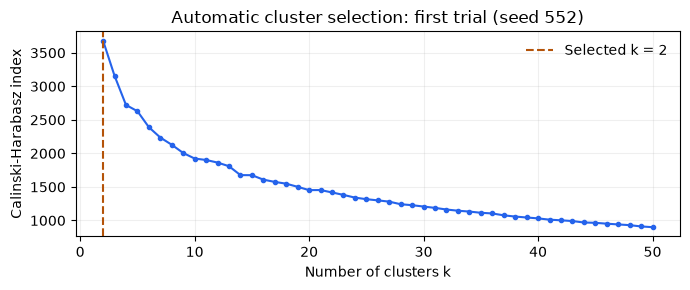

In [8]:
cluster_start = time.perf_counter()
N_TRIALS = 50
CLUSTER_SEEDS = range(SEED, SEED + N_TRIALS)
# Independent random initializations; every candidate uses all observations.
# Two workers and one numerical-library thread per worker prevent oversubscription.
with parallel_config(backend="loky", inner_max_num_threads=1):
    cluster_trials = Parallel(n_jobs=2)(
        delayed(one_trial)(X_cluster, seed) for seed in CLUSTER_SEEDS
    )
assert len(cluster_trials) == N_TRIALS
print(f"Completed {N_TRIALS} trials in {time.perf_counter() - cluster_start:.1f} seconds.")
selected_k_counts = pd.Series([t["k"] for t in cluster_trials]).value_counts().sort_index()
display(selected_k_counts.rename_axis("Selected k").to_frame("Number of trials"))

first_candidates = pd.DataFrame(cluster_trials[0]["candidates"], columns=["k", "inertia", "CH"])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(first_candidates["k"], first_candidates["CH"], marker=".", color="#2563eb")
ax.axvline(cluster_trials[0]["k"], color="#b45309", linestyle="--",
           label=f"Selected k = {cluster_trials[0]['k']}")
ax.set(xlabel="Number of clusters k", ylabel="Calinski-Harabasz index",
       title=f"Automatic cluster selection: first trial (seed {SEED})")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### (b) Majority family, genus, and species in each cluster

I assign each cluster the most common family, genus, and species, calculated
separately. Ties are broken alphabetically. This is repeated for all 50 trials;
the tables show the first trial's labels and within-cluster agreement.

In [9]:
def assign_majorities(y, assignments):
    predictions = pd.DataFrame(index=y.index, columns=y.columns, dtype=object)
    rows = []
    for cluster in np.unique(assignments):
        mask = assignments == cluster
        # pandas.mode() sorts tied values, giving deterministic tie breaking.
        majority = y.loc[mask].mode().iloc[0]
        predictions.loc[mask, :] = majority.to_numpy()
        row = {'cluster': int(cluster), 'size': int(mask.sum())}
        for label in y.columns:
            row[label] = majority[label]
            row[label + '_fraction'] = float((y.loc[mask, label] == majority[label]).mean())
        rows.append(row)
    return predictions, pd.DataFrame(rows)


cluster_rows = []
cluster_majority_tables = []
for trial_number, trial in enumerate(cluster_trials, start=1):
    prediction, majority_table = assign_majorities(y_cluster, trial["labels"])
    mismatch = y_cluster.to_numpy() != prediction.to_numpy()
    distance = float(mismatch.sum(axis=1).mean())
    loss = float(mismatch.mean())
    assert np.isclose(distance, 3 * loss)
    cluster_rows.append({
        "trial": trial_number, "seed": trial["seed"], "selected_k": trial["k"],
        "CH": trial["ch"], "hamming_distance": distance,
        "hamming_loss": loss, "hamming_score": 1 - loss,
        "exact_match": float((~mismatch.any(axis=1)).mean()),
    })
    cluster_majority_tables.append(majority_table)
cluster_results = pd.DataFrame(cluster_rows)
print("Majority labels for the first trial; each fraction is the within-cluster agreement.")
first_majorities = cluster_majority_tables[0]
display(first_majorities[['cluster', 'size', *svm_labels]])
display(first_majorities[['cluster'] + [label + '_fraction' for label in svm_labels]].round(4))
assert all(table["size"].sum() == len(cluster_data) for table in cluster_majority_tables)

Majority labels for the first trial; each fraction is the within-cluster agreement.


,cluster,size,Family,Genus,Species
0,0,3597,Hylidae,Hypsiboas,HypsiboasCordobae
1,1,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


,cluster,Family_fraction,Genus_fraction,Species_fraction
0,0,0.5674,0.4390,0.3078
1,1,0.9655,0.9644,0.9644


### (c) Hamming evaluation across 50 trials

I use the Hamming metrics defined in 1(b)(i) and report the mean and sample
standard deviation (`ddof=1`) across the 50 trials. These are in-sample
agreement scores because the true labels determine each cluster's majority
triplet; they are not held-out test accuracies.

,hamming_distance,hamming_score,hamming_loss,exact_match
Mean (50 trials),0.895622,0.701459,0.298541,0.636136
Sample SD (ddof=1),0.000000,0.000000,0.000000,0.000000


,selected_k,hamming_distance,hamming_score,hamming_loss,exact_match,Trials
0,2,0.895622,0.701459,0.298541,0.636136,50


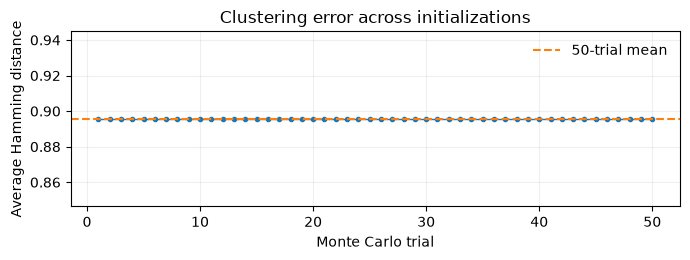

In [10]:
cluster_metrics = ['hamming_distance', 'hamming_score', 'hamming_loss', 'exact_match']
cluster_summary = cluster_results[cluster_metrics].agg(['mean', 'std'])
cluster_summary.index = ['Mean (50 trials)', 'Sample SD (ddof=1)']
display(cluster_summary.round(6))
# Retain every trial in cluster_results; group repeated results for compact display.
outcomes = cluster_results.groupby(['selected_k'] + cluster_metrics).size()
display(outcomes.rename('Trials').reset_index().round(6))
assert outcomes.sum() == 50
assert np.allclose(cluster_results.hamming_distance, 3 * cluster_results.hamming_loss)
fig, ax = plt.subplots(figsize=(7, 2.7))
ax.plot(cluster_results.trial, cluster_results.hamming_distance, '.-', linewidth=1)
ax.axhline(cluster_results.hamming_distance.mean(), color='tab:orange',
           linestyle='--', label='50-trial mean')
ax.set(xlabel='Monte Carlo trial', ylabel='Average Hamming distance',
       title='Clustering error across initializations')
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

All 50 trials select $k=2$ and give the same Hamming distance. The zero
standard deviation shows stability across these initializations, not a lack
of uncertainty about new data. CH favors geometric separation, so its two
clusters do not recover all of the biological categories.

## 3. ISLR 12.6.2

*An Introduction to Statistical Learning*, 2nd edition, Exercise 12.6.2 (p. 546). The dissimilarity matrix is

$$
D=\begin{pmatrix}
0 & 0.30 & 0.40 & 0.70\\
0.30 & 0 & 0.50 & 0.80\\
0.40 & 0.50 & 0 & 0.45\\
0.70 & 0.80 & 0.45 & 0
\end{pmatrix}.
$$

**(a) Complete linkage.** The distance between two clusters is the largest dissimilarity between their members:
$$d_{\mathrm{complete}}(A,B)=\max_{i\in A,j\in B}D_{ij}.$$
The smallest initial distance is $D_{12}=0.30$, so observations 1 and 2 merge first. The remaining distances are
$$\begin{aligned}
d(\{1,2\},\{3\})&=\max(0.40,0.50)=0.50,\\
d(\{1,2\},\{4\})&=\max(0.70,0.80)=0.80,\\
d(\{3\},\{4\})&=0.45.
\end{aligned}$$
Thus 3 and 4 merge at height 0.45. Finally, $\{1,2\}$ and $\{3,4\}$ merge at $\max(0.40,0.70,0.50,0.80)=0.80$.

**(b) Single linkage.** Here we use the smallest cross-cluster dissimilarity:
$$d_{\mathrm{single}}(A,B)=\min_{i\in A,j\in B}D_{ij}.$$
Observations 1 and 2 again merge at 0.30. Next, $d(\{1,2\},\{3\})=\min(0.40,0.50)=0.40$, which is less than 0.45 and $d(\{1,2\},\{4\})=0.70$. Therefore 3 joins $\{1,2\}$ at 0.40. Observation 4 joins at $\min(0.70,0.80,0.45)=0.45$.

**(c)** Cutting the complete-linkage dendrogram at any height strictly between 0.45 and 0.80 gives $\boxed{\{1,2\},\{3,4\}}$.

**(d)** Cutting the single-linkage dendrogram at any height strictly between 0.40 and 0.45 gives $\boxed{\{1,2,3\},\{4\}}$.

**(e)** Swap the positions of leaves 1 and 2 in the complete-linkage tree, giving leaf order 2, 1, 3, 4. This preserves all cluster memberships and fusion heights (0.30, 0.45, and 0.80), so it represents the same hierarchy. The third plot below shows this equivalent dendrogram.

The red dashed lines mark the two-cluster cuts: 0.60 for complete linkage and 0.425 for single linkage.

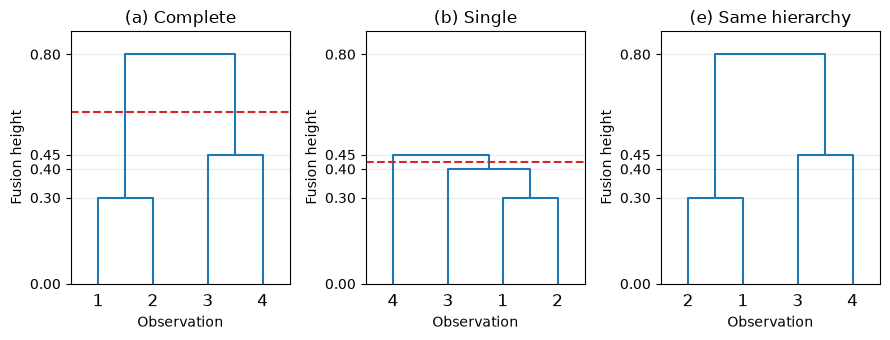

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

D = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00],
])
complete = linkage(squareform(D), method="complete")
single = linkage(squareform(D), method="single")
equivalent = complete.copy()
equivalent[0, :2] = equivalent[0, 1::-1]  # swap leaves, preserving tree

fig, axes = plt.subplots(1, 3, figsize=(9, 3.5))
for ax, tree, title in zip(
    axes,
    [complete, single, equivalent],
    ["(a) Complete", "(b) Single", "(e) Same hierarchy"],
):
    dendrogram(tree, labels=["1", "2", "3", "4"], ax=ax,
               color_threshold=0, above_threshold_color="tab:blue")
    ax.set(title=title, xlabel="Observation", ylabel="Fusion height")
    ax.set_ylim(0, 0.88)
    ax.set_yticks([0, 0.30, 0.40, 0.45, 0.80])
    ax.grid(axis="y", alpha=0.25)
axes[0].axhline(0.60, color="tab:red", linestyle="--", label="Two-cluster cut")
axes[1].axhline(0.425, color="tab:red", linestyle="--", label="Two-cluster cut")
fig.tight_layout()
plt.show()

# Verify the drawn merge heights against the hand calculations.
assert np.allclose(complete[:, 2], [0.30, 0.45, 0.80])
assert np.allclose(single[:, 2], [0.30, 0.40, 0.45])